# 01 - Análisis exploratorio de datos (EDA)

**Proyecto:** Predicción de ausentismo a turnos médicos (*No-Show*)
**Fase CRISP-DM:** Comprensión de los datos

**Objetivo:** describir el dataset y cada atributo, evaluar la calidad de los datos con evidencia concreta, analizar el desbalance de la variable objetivo e identificar qué atributos se relacionan con el ausentismo. Las conclusiones de este notebook definen las decisiones de limpieza y preparación del notebook `02_preparacion.ipynb`.

**Salidas:**
- Figuras numeradas en `reports/figures/` (prefijo `eda_`).
- Tablas en `reports/tables/` (prefijo `eda_`).
- Resumen de cifras clave en `reports/tables/eda_resumen.md`.

> Este notebook **no modifica** los datos originales. Las columnas derivadas que se crean acá (anticipación, día de la semana, etc.) son solo exploratorias; las transformaciones definitivas se aplican en el notebook 02.

## 0. Configuración

In [1]:
# Interruptor de datos: True = muestra de desarrollo, False = dataset completo
USAR_MUESTRA = False

In [2]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score
from sklearn.model_selection import StratifiedKFold, cross_validate

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src import config
from src.data import cargar_datos_crudos
from src.reporting import guardar_figura, guardar_tabla, tabla_markdown

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

COLOR_ASISTE = "#4C72B0"
COLOR_NO_ASISTE = "#DD8452"
PALETA = {"Asiste": COLOR_ASISTE, "No asiste": COLOR_NO_ASISTE}

# Diccionario donde se acumulan las cifras clave para eda_resumen.md
resumen = {"Datos utilizados": "Muestra de desarrollo" if USAR_MUESTRA else "Dataset completo"}

In [3]:
def tasa_con_ic(exitos, n, z=1.96):
    """Proporción con intervalo de confianza de Wilson al 95%."""
    exitos, n = np.asarray(exitos, float), np.asarray(n, float)
    p = exitos / n
    denom = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denom
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return p, centro - margen, centro + margen


def tasa_por(data, col, orden=None):
    """Tabla de tasa de no-show por categoría, con n e intervalo de confianza."""
    g = data.groupby(col, observed=True)["no_show"].agg(n="size", ausencias="sum")
    if orden is not None:
        g = g.reindex(orden)
    g["tasa"], g["ic_inf"], g["ic_sup"] = tasa_con_ic(g["ausencias"], g["n"])
    return g


def graficar_tasa(ax, tabla, titulo, etiqueta_x="", rotar=0):
    """Barras de tasa de no-show con IC 95% y línea de la tasa global."""
    x = np.arange(len(tabla))
    err = np.vstack([tabla["tasa"] - tabla["ic_inf"], tabla["ic_sup"] - tabla["tasa"]])
    ax.bar(x, tabla["tasa"], yerr=err, color=COLOR_NO_ASISTE, alpha=0.85, capsize=3)
    ax.axhline(TASA_GLOBAL, color="gray", ls="--", lw=1, label=f"Tasa global ({TASA_GLOBAL:.1%})")
    ax.set_xticks(x)
    ax.set_xticklabels(tabla.index.astype(str), rotation=rotar, ha="right" if rotar else "center")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Tasa de no-show")
    ax.legend(loc="upper right", fontsize=8)

## 1. Estructura del dataset

### 1.1. Carga y vista general

In [4]:
df = cargar_datos_crudos(usar_muestra=USAR_MUESTRA)

n_filas, n_cols = df.shape
resumen["Instancias (turnos)"] = f"{n_filas:,}"
resumen["Atributos"] = n_cols
print(f"Instancias: {n_filas:,} | Atributos: {n_cols}")
df.head()

Instancias: 110,527 | Atributos: 14


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,29872499824296,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,558997776694438,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4262962299951,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,867951213174,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8841186448183,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   PatientId       110527 non-null  object
 1   AppointmentID   110527 non-null  int64 
 2   Gender          110527 non-null  object
 3   ScheduledDay    110527 non-null  object
 4   AppointmentDay  110527 non-null  object
 5   Age             110527 non-null  int64 
 6   Neighbourhood   110527 non-null  object
 7   Scholarship     110527 non-null  int64 
 8   Hipertension    110527 non-null  int64 
 9   Diabetes        110527 non-null  int64 
 10  Alcoholism      110527 non-null  int64 
 11  Handcap         110527 non-null  int64 
 12  SMS_received    110527 non-null  int64 
 13  No-show         110527 non-null  object
dtypes: int64(8), object(6)
memory usage: 11.8+ MB


### 1.2. Columnas derivadas para la exploración

Para poder analizar los datos se crean, **solo en una copia de trabajo**, algunas columnas auxiliares:

- `no_show`: variable objetivo numérica (1 = no asistió, 0 = asistió).
- `fecha_agenda` y `fecha_turno`: fechas convertidas a tipo fecha.
- `anticipacion_dias`: días entre el agendamiento y el turno.
- `dia_semana`: día de la semana del turno.

In [6]:
eda = df.copy()
eda["no_show"] = (eda["No-show"] == "Yes").astype(int)
eda["asistencia"] = np.where(eda["no_show"] == 1, "No asiste", "Asiste")

agenda = pd.to_datetime(eda["ScheduledDay"], utc=True)
turno = pd.to_datetime(eda["AppointmentDay"], utc=True)
eda["fecha_agenda"] = agenda.dt.tz_localize(None)
eda["fecha_turno"] = turno.dt.tz_localize(None)
eda["anticipacion_dias"] = (turno.dt.normalize() - agenda.dt.normalize()).dt.days

DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
eda["dia_semana"] = pd.Categorical(
    eda["fecha_turno"].dt.dayofweek.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True
)

TASA_GLOBAL = eda["no_show"].mean()
eda[["no_show", "fecha_agenda", "fecha_turno", "anticipacion_dias", "dia_semana"]].head()

,no_show,fecha_agenda,fecha_turno,anticipacion_dias,dia_semana
0,0,2016-04-29 18:38:08,2016-04-29,0,Viernes
1,0,2016-04-29 16:08:27,2016-04-29,0,Viernes
2,0,2016-04-29 16:19:04,2016-04-29,0,Viernes
3,0,2016-04-29 17:29:31,2016-04-29,0,Viernes
4,0,2016-04-29 16:07:23,2016-04-29,0,Viernes


### 1.3. Diccionario de datos

Descripción de cada atributo según la documentación del dataset en Kaggle, con su tipo semántico y los valores observados.

In [7]:
descripciones = {
    "PatientId": ("Identificador del paciente", "Identificador"),
    "AppointmentID": ("Identificador del turno", "Identificador"),
    "Gender": ("Género del paciente (F/M)", "Categórico binario"),
    "ScheduledDay": ("Fecha y hora en que se agendó el turno", "Fecha-hora"),
    "AppointmentDay": ("Fecha del turno", "Fecha"),
    "Age": ("Edad del paciente en años", "Numérico discreto"),
    "Neighbourhood": ("Barrio donde se realiza la atención", "Categórico nominal"),
    "Scholarship": ("Inscripto en el programa social Bolsa Família (1 = sí)", "Categórico binario"),
    "Hipertension": ("Tiene hipertensión (1 = sí)", "Categórico binario"),
    "Diabetes": ("Tiene diabetes (1 = sí)", "Categórico binario"),
    "Alcoholism": ("Tiene alcoholismo (1 = sí)", "Categórico binario"),
    "Handcap": ("Cantidad de discapacidades (0 a 4)", "Numérico discreto"),
    "SMS_received": ("Recibió al menos un SMS recordatorio (1 = sí)", "Categórico binario"),
    "No-show": ("No asistió al turno (Yes = no asistió) - VARIABLE OBJETIVO", "Categórico binario"),
}


def valores_observados(s):
    if s.name in ("ScheduledDay", "AppointmentDay"):
        f = pd.to_datetime(s, utc=True)
        return f"{f.min().date()} a {f.max().date()}"
    if s.name in ("PatientId", "AppointmentID"):
        return f"{s.nunique():,} valores únicos"
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 10:
        return f"{s.min()} a {s.max()}"
    if s.nunique() <= 10:
        return ", ".join(map(str, sorted(s.unique())))
    return f"{s.nunique()} categorías"


diccionario = pd.DataFrame(
    [
        {
            "Atributo": c,
            "Descripción": descripciones[c][0],
            "Tipo": descripciones[c][1],
            "Tipo pandas": str(df[c].dtype),
            "Valores observados": valores_observados(df[c]),
        }
        for c in df.columns
    ]
)
guardar_tabla(diccionario, "eda_diccionario_datos")
diccionario

,Atributo,Descripción,Tipo,Tipo pandas,Valores observados
0,PatientId,Identificador del paciente,Identificador,object,"62,299 valores únicos"
1,AppointmentID,Identificador del turno,Identificador,int64,"110,527 valores únicos"
2,Gender,Género del paciente (F/M),Categórico binario,object,"F, M"
3,ScheduledDay,Fecha y hora en que se agendó el turno,Fecha-hora,object,2015-11-10 a 2016-06-08
4,AppointmentDay,Fecha del turno,Fecha,object,2016-04-29 a 2016-06-08
5,Age,Edad del paciente en años,Numérico discreto,int64,-1 a 115
6,Neighbourhood,Barrio donde se realiza la atención,Categórico nominal,object,81 categorías
7,Scholarship,Inscripto en el programa social Bolsa Família ...,Categórico binario,int64,"0, 1"
8,Hipertension,Tiene hipertensión (1 = sí),Categórico binario,int64,"0, 1"
9,Diabetes,Tiene diabetes (1 = sí),Categórico binario,int64,"0, 1"


**Observaciones sobre los nombres de columnas:** `Hipertension` y `Handcap` tienen errores de escritura y `No-show` incluye un guion. Se renombrarán en la preparación para mantener un estilo consistente.

## 2. Calidad de los datos

Se revisan sistemáticamente cinco dimensiones de calidad: completitud, unicidad, validez de rangos, consistencia temporal y consistencia entre registros del mismo paciente.

### 2.1. Valores faltantes

In [8]:
faltantes = df.isna().sum().to_frame("faltantes")
faltantes["porcentaje"] = faltantes["faltantes"] / len(df) * 100
n_faltantes = int(faltantes["faltantes"].sum())
print(f"Total de valores faltantes: {n_faltantes}")
faltantes.T

Total de valores faltantes: 0


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
faltantes,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
porcentaje,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### 2.2. Duplicados

In [9]:
dup_exactos = df.duplicated().sum()
dup_id_turno = df["AppointmentID"].duplicated().sum()
cols_sin_id = [c for c in df.columns if c != "AppointmentID"]
dup_sin_id = df.duplicated(subset=cols_sin_id).sum()

print(f"Filas duplicadas exactas:                      {dup_exactos}")
print(f"AppointmentID repetidos:                       {dup_id_turno}")
print(f"Filas idénticas salvo AppointmentID:           {dup_sin_id}")

Filas duplicadas exactas:                      0
AppointmentID repetidos:                       0
Filas idénticas salvo AppointmentID:           618


**Mismo paciente con varios turnos el mismo día.** Pueden ser turnos distintos (por ejemplo, con dos especialidades) o el mismo evento cargado más de una vez. Interesa saber cuántos son y si el paciente asiste o falta a todos juntos: si el resultado es casi siempre el mismo, estos registros comparten información y deben quedar del mismo lado en la partición entrenamiento/prueba.

In [10]:
clave_dia = [eda["PatientId"], eda["fecha_turno"].dt.date]
eda["turnos_mismo_dia"] = eda.groupby(clave_dia)["AppointmentID"].transform("size")

grupos = eda[eda["turnos_mismo_dia"] > 1].groupby(
    [eda["PatientId"], eda["fecha_turno"].dt.date]
)
n_grupos_multi = grupos.ngroups
n_filas_multi = int((eda["turnos_mismo_dia"] > 1).sum())
consistentes = grupos["no_show"].nunique().eq(1).mean() if n_grupos_multi else np.nan
mismo_agendamiento = grupos["ScheduledDay"].nunique().eq(1).mean() if n_grupos_multi else np.nan

print(f"Grupos paciente-día con más de un turno:   {n_grupos_multi:,}")
print(f"Filas involucradas:                        {n_filas_multi:,} ({n_filas_multi / len(eda):.1%})")
print(f"Grupos con el mismo resultado en todos:    {consistentes:.1%}")
print(f"Grupos agendados en el mismo instante:     {mismo_agendamiento:.1%}")
print()
print("Tasa de no-show según cantidad de turnos del paciente ese día:")
tasa_por(eda, "turnos_mismo_dia").head(6)

Grupos paciente-día con más de un turno:   7,481
Filas involucradas:                        16,200 (14.7%)
Grupos con el mismo resultado en todos:    82.1%
Grupos agendados en el mismo instante:     15.6%

Tasa de no-show según cantidad de turnos del paciente ese día:


,n,ausencias,tasa,ic_inf,ic_sup
turnos_mismo_dia,,,,,
1,94327,18746,0.1987,0.1962,0.2013
2,13064,2929,0.2242,0.2171,0.2314
3,2217,484,0.2183,0.2016,0.2360
4,628,119,0.1895,0.1608,0.2220
5,165,21,0.1273,0.0848,0.1867
6,108,14,0.1296,0.0788,0.2059


### 2.3. Validez de rangos

In [11]:
binarias = ["Scholarship", "Hipertension", "Diabetes", "Alcoholism", "SMS_received"]
fuera_binario = {c: int((~df[c].isin([0, 1])).sum()) for c in binarias}
print("Valores fuera de {0, 1} en atributos binarios:", fuera_binario)
print("Valores de Gender:", df["Gender"].value_counts().to_dict())
print("Valores de No-show:", df["No-show"].value_counts().to_dict())
print()

edad_neg = int((df["Age"] < 0).sum())
edad_cero = int((df["Age"] == 0).sum())
edad_mayor100 = int((df["Age"] > 100).sum())
print(f"Edad < 0:    {edad_neg}  -> valores: {sorted(df.loc[df['Age'] < 0, 'Age'].unique())}")
print(f"Edad = 0:    {edad_cero:,} (bebés menores de un año: valor plausible)")
print(f"Edad > 100:  {edad_mayor100}  -> valores: {sorted(df.loc[df['Age'] > 100, 'Age'].unique())}")
print()
print("Distribución de Handcap:")
print(df["Handcap"].value_counts().sort_index().to_string())
handcap_mayor1 = int((df["Handcap"] > 1).sum())

Valores fuera de {0, 1} en atributos binarios: {'Scholarship': 0, 'Hipertension': 0, 'Diabetes': 0, 'Alcoholism': 0, 'SMS_received': 0}
Valores de Gender: {'F': 71840, 'M': 38687}
Valores de No-show: {'No': 88208, 'Yes': 22319}

Edad < 0:    1  -> valores: [np.int64(-1)]
Edad = 0:    3,539 (bebés menores de un año: valor plausible)
Edad > 100:  7  -> valores: [np.int64(102), np.int64(115)]

Distribución de Handcap:
Handcap
0    108286
1      2042
2       183
3        13
4         3


### 2.4. Consistencia temporal

In [12]:
anticipacion_neg = int((eda["anticipacion_dias"] < 0).sum())
turno_con_hora = int((eda["fecha_turno"].dt.hour != 0).sum())
n_sabado = int((eda["dia_semana"] == "Sábado").sum())
n_domingo = int((eda["dia_semana"] == "Domingo").sum())

print(f"Rango de fechas de agendamiento: {eda['fecha_agenda'].min():%Y-%m-%d} a {eda['fecha_agenda'].max():%Y-%m-%d}")
print(f"Rango de fechas de turno:        {eda['fecha_turno'].min():%Y-%m-%d} a {eda['fecha_turno'].max():%Y-%m-%d}")
print(f"Días distintos con turnos:       {eda['fecha_turno'].dt.date.nunique()}")
print(f"Turnos anteriores a su fecha de agendamiento: {anticipacion_neg}")
print(f"Turnos con hora distinta de 00:00:            {turno_con_hora} (AppointmentDay no registra la hora)")
print(f"Turnos en sábado: {n_sabado} | en domingo: {n_domingo}")
print()
print("Detalle de los turnos con anticipación negativa:")
eda.loc[eda["anticipacion_dias"] < 0, ["PatientId", "ScheduledDay", "AppointmentDay", "anticipacion_dias", "No-show"]]

Rango de fechas de agendamiento: 2015-11-10 a 2016-06-08
Rango de fechas de turno:        2016-04-29 a 2016-06-08
Días distintos con turnos:       27
Turnos anteriores a su fecha de agendamiento: 5
Turnos con hora distinta de 00:00:            0 (AppointmentDay no registra la hora)
Turnos en sábado: 39 | en domingo: 0

Detalle de los turnos con anticipación negativa:


,PatientId,ScheduledDay,AppointmentDay,anticipacion_dias,No-show
27033,7839272661752,2016-05-10T10:51:53Z,2016-05-09T00:00:00Z,-1,Yes
55226,7896293967868,2016-05-18T14:50:41Z,2016-05-17T00:00:00Z,-1,Yes
64175,24252258389979,2016-05-05T13:43:58Z,2016-05-04T00:00:00Z,-1,Yes
71533,998231581612122,2016-05-11T13:49:20Z,2016-05-05T00:00:00Z,-6,Yes
72362,3787481966821,2016-05-04T06:50:57Z,2016-05-03T00:00:00Z,-1,Yes


### 2.5. Consistencia de los identificadores y de los datos del paciente

Un mismo `PatientId` debería tener siempre el mismo género y una edad que varíe como mucho un año dentro del período.

In [13]:
patron_entero = r"^\d+(\.0)?$"
id_irregular = int((~df["PatientId"].str.match(patron_entero)).sum())
print(f"PatientId con formato no entero: {id_irregular} -> {df.loc[~df['PatientId'].str.match(patron_entero), 'PatientId'].tolist()[:5]}")

por_paciente = eda.groupby("PatientId").agg(
    generos=("Gender", "nunique"), edad_min=("Age", "min"), edad_max=("Age", "max"), turnos=("AppointmentID", "size")
)
genero_inconsistente = int((por_paciente["generos"] > 1).sum())
edad_inconsistente = int(((por_paciente["edad_max"] - por_paciente["edad_min"]) > 1).sum())
print(f"Pacientes con más de un género registrado:      {genero_inconsistente}")
print(f"Pacientes con edades que difieren más de 1 año: {edad_inconsistente}")

PatientId con formato no entero: 5 -> ['9377952927E-5', '53761528476E-5', '14172416655E-5', '3921784439E-5', '4374175652E-5']
Pacientes con más de un género registrado:      0
Pacientes con edades que difieren más de 1 año: 0


### 2.6. Cardinalidad de `Neighbourhood`

In [14]:
conteo_barrios = df["Neighbourhood"].value_counts()
UMBRAL_BARRIO = 50
barrios_chicos = conteo_barrios[conteo_barrios < UMBRAL_BARRIO]
print(f"Barrios distintos: {conteo_barrios.size}")
print(f"Barrios con menos de {UMBRAL_BARRIO} turnos: {barrios_chicos.size} "
      f"({barrios_chicos.sum():,} turnos, {barrios_chicos.sum() / len(df):.2%} del total)")
print()
print("Barrios con menos turnos:")
conteo_barrios.tail(8)

Barrios distintos: 81
Barrios con menos de 50 turnos: 5 (56 turnos, 0.05% del total)

Barrios con menos turnos:


Neighbourhood
NAZARETH                       135
MORADA DE CAMBURI               96
PONTAL DE CAMBURI               69
ILHA DO BOI                     35
ILHA DO FRADE                   10
AEROPORTO                        8
ILHAS OCEÂNICAS DE TRINDADE      2
PARQUE INDUSTRIAL                1
Name: count, dtype: int64

### 2.7. Resumen de problemas de calidad

Tabla consolidada con la evidencia encontrada y la acción propuesta para el notebook de preparación.

In [15]:
pct = lambda n: f"{n / len(df):.3%}"
problemas = pd.DataFrame(
    [
        ("Valores faltantes", f"{n_faltantes} valores", "No requiere acción"),
        ("Filas duplicadas exactas", f"{dup_exactos} filas", "No requiere acción"),
        ("Varios turnos del mismo paciente el mismo día",
         f"{n_filas_multi:,} filas ({n_filas_multi / len(df):.1%}); {consistentes:.0%} de los grupos con igual resultado",
         "Conservar como turnos distintos; partición agrupada por paciente para evitar fuga"),
        ("Edad negativa", f"{edad_neg} fila(s) ({pct(edad_neg)})", "Eliminar"),
        ("Edad mayor a 100 años", f"{edad_mayor100} filas ({pct(edad_mayor100)})", "Revisar plausibilidad; eliminar valores imposibles"),
        ("Handcap con valores 2 a 4", f"{handcap_mayor1} filas ({pct(handcap_mayor1)})", "Es un conteo, no un error: conservar o binarizar (> 0)"),
        ("Turno anterior al agendamiento", f"{anticipacion_neg} filas ({pct(anticipacion_neg)})", "Eliminar (inconsistencia temporal)"),
        ("AppointmentDay sin hora", f"{len(df) - turno_con_hora:,} filas (100%)", "No se puede usar la hora del turno como atributo"),
        ("Turnos en sábado", f"{n_sabado} filas ({pct(n_sabado)})", "Categoría casi vacía: agrupar o tratar con cuidado"),
        ("PatientId con formato irregular", f"{id_irregular} fila(s)", "Conservar (solo se usa como identificador de grupo)"),
        ("Género inconsistente por paciente", f"{genero_inconsistente} pacientes", "No requiere acción" if genero_inconsistente == 0 else "Revisar"),
        (f"Barrios con menos de {UMBRAL_BARRIO} turnos", f"{barrios_chicos.size} barrios ({barrios_chicos.sum():,} turnos)",
         "Agrupar en 'Otros' o usar codificación por frecuencia/objetivo"),
        ("Nombres de columnas con errores", "Hipertension, Handcap, No-show", "Renombrar"),
    ],
    columns=["Problema", "Evidencia", "Acción propuesta"],
)
guardar_tabla(problemas, "eda_calidad_problemas")
problemas

,Problema,Evidencia,Acción propuesta
0,Valores faltantes,0 valores,No requiere acción
1,Filas duplicadas exactas,0 filas,No requiere acción
2,Varios turnos del mismo paciente el mismo día,"16,200 filas (14.7%); 82% de los grupos con ig...",Conservar como turnos distintos; partición agr...
3,Edad negativa,1 fila(s) (0.001%),Eliminar
4,Edad mayor a 100 años,7 filas (0.006%),Revisar plausibilidad; eliminar valores imposi...
5,Handcap con valores 2 a 4,199 filas (0.180%),"Es un conteo, no un error: conservar o binariz..."
6,Turno anterior al agendamiento,5 filas (0.005%),Eliminar (inconsistencia temporal)
7,AppointmentDay sin hora,"110,527 filas (100%)",No se puede usar la hora del turno como atributo
8,Turnos en sábado,39 filas (0.035%),Categoría casi vacía: agrupar o tratar con cui...
9,PatientId con formato irregular,5 fila(s),Conservar (solo se usa como identificador de g...


## 3. Variable objetivo y desbalance de clases

Siguiendo la recomendación de la docente, el desbalance se analiza **antes** de cualquier entrenamiento, porque condiciona la elección de las métricas y la estrategia de modelado.

### 3.1. Distribución de la variable objetivo

Relación de clases: 3.95 turnos con asistencia por cada ausencia


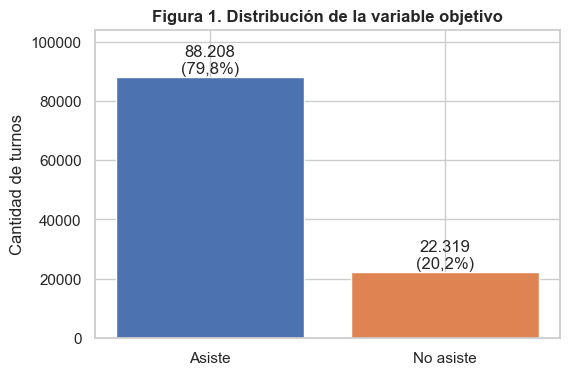

,n,porcentaje
asistencia,,
Asiste,88208,79.8067
No asiste,22319,20.1933


In [16]:
dist = eda["asistencia"].value_counts().reindex(["Asiste", "No asiste"]).to_frame("n")
dist["porcentaje"] = dist["n"] / dist["n"].sum() * 100
ratio = dist.loc["Asiste", "n"] / dist.loc["No asiste", "n"]
resumen["Tasa de no-show"] = f"{TASA_GLOBAL:.2%}"
resumen["Relación de clases (asiste : no asiste)"] = f"{ratio:.2f} : 1"
print(f"Relación de clases: {ratio:.2f} turnos con asistencia por cada ausencia")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(dist.index, dist["n"], color=[COLOR_ASISTE, COLOR_NO_ASISTE])
for i, (n, p) in enumerate(zip(dist["n"], dist["porcentaje"])):
    ax.text(i, n, f"{n:,}".replace(",", ".") + f"\n({p:.1f}%)".replace(".", ","), ha="center", va="bottom")
ax.set_title("Figura 1. Distribución de la variable objetivo")
ax.set_ylabel("Cantidad de turnos")
ax.set_ylim(0, dist["n"].max() * 1.18)
guardar_figura(fig, "eda_01_distribucion_objetivo")
plt.show()
dist

### 3.2. Efecto del desbalance sobre las métricas: clasificadores triviales

Se evalúan dos clasificadores que **no usan ningún atributo**, con validación cruzada estratificada de 5 particiones:

- **Clase mayoritaria:** siempre predice "asiste".
- **Aleatorio estratificado:** predice al azar respetando la proporción de clases.

Cualquier modelo útil debe superarlos claramente. Esta comparación muestra por qué la exactitud no sirve como métrica principal en este problema.

In [17]:
X_vacio = np.zeros((len(eda), 1))
y = eda["no_show"].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.SEED)
metricas = {
    "Exactitud": "accuracy",
    "Exactitud balanceada": "balanced_accuracy",
    "Precisión (no-show)": make_scorer(precision_score, zero_division=0),
    "Recall (no-show)": "recall",
    "F1 (no-show)": "f1",
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
}
filas = []
for nombre, estrategia in [("Clase mayoritaria", "most_frequent"), ("Aleatorio estratificado", "stratified")]:
    res = cross_validate(DummyClassifier(strategy=estrategia, random_state=config.SEED),
                         X_vacio, y, cv=cv, scoring=metricas)
    filas.append({"Clasificador": nombre, **{k: res[f"test_{k}"].mean() for k in metricas}})

baseline_dummy = pd.DataFrame(filas).set_index("Clasificador")
guardar_tabla(baseline_dummy, "eda_baseline_dummy", index=True)
resumen["Exactitud del clasificador trivial (clase mayoritaria)"] = f"{baseline_dummy.iloc[0]['Exactitud']:.2%}"
baseline_dummy

,Exactitud,Exactitud balanceada,Precisión (no-show),Recall (no-show),F1 (no-show),ROC-AUC,PR-AUC
Clasificador,,,,,,,
Clase mayoritaria,0.7981,0.5000,0.0000,0.0000,0.0000,0.5000,0.2019
Aleatorio estratificado,0.6782,0.5015,0.2043,0.2050,0.2047,0.5015,0.2024


**Lectura de los resultados:**

- El clasificador que siempre predice "asiste" logra una **exactitud cercana al 80%** sin detectar **ninguna** ausencia (recall = 0). La exactitud premia acertar la clase mayoritaria y esconde que el modelo no resuelve el problema.
- Su **PR-AUC** coincide con la tasa de no-show: ese es el piso que debe superar un modelo con capacidad real de discriminación. La ROC-AUC de un clasificador sin información es 0,5.

**Decisiones que se derivan del análisis del desbalance:**

1. **Métricas principales:** PR-AUC, ROC-AUC, recall y F1 de la clase *no-show*, y exactitud balanceada. La exactitud se informa solo como referencia.
2. **Partición estratificada** por la variable objetivo, para que entrenamiento y prueba conserven la proporción de clases.
3. **Comparación de estrategias de tratamiento** (sin tratamiento, ponderación de clases, submuestreo y SMOTE), aplicadas solo sobre los datos de entrenamiento.
4. **Ajuste del umbral de decisión:** el umbral de 0,5 no es adecuado con clases desbalanceadas; se ajustará sobre datos de validación.

## 4. Análisis univariado

### 4.1. Atributos numéricos

In [18]:
num = eda[["Age", "anticipacion_dias", "Handcap"]].describe().T
num["asimetría"] = eda[["Age", "anticipacion_dias", "Handcap"]].skew()
guardar_tabla(num, "eda_estadisticos_numericos", index=True)
num

,count,mean,std,min,25%,50%,75%,max,asimetría
Age,"110,527.0000",37.0889,23.1102,-1.0000,18.0000,37.0000,55.0000,115.0000,0.1217
anticipacion_dias,"110,527.0000",10.1837,15.2550,-6.0000,0.0000,4.0000,15.0000,179.0000,2.6659
Handcap,"110,527.0000",0.0222,0.1615,0.0000,0.0000,0.0000,0.0000,4.0000,8.2744


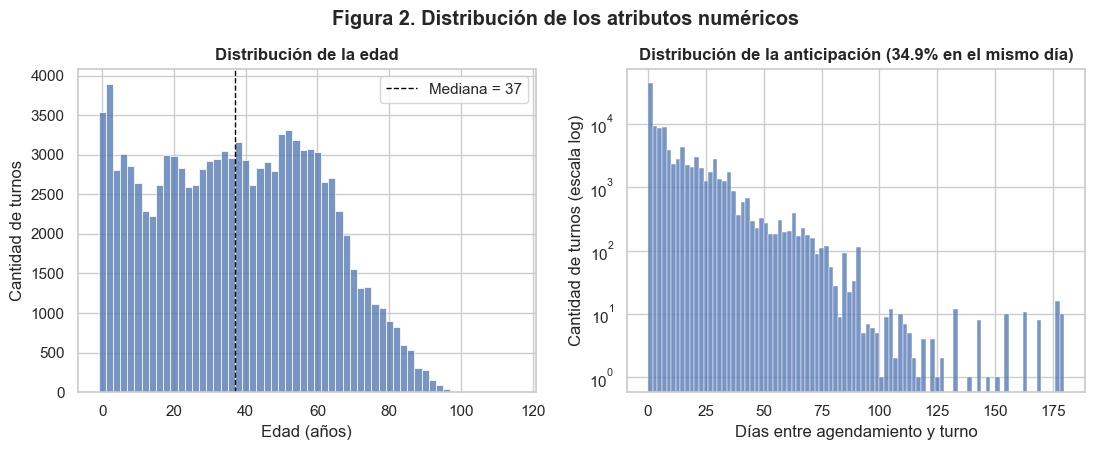

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

sns.histplot(eda["Age"], bins=range(-1, 117, 2), color=COLOR_ASISTE, ax=axes[0])
axes[0].axvline(eda["Age"].median(), color="black", ls="--", lw=1, label=f"Mediana = {eda['Age'].median():.0f}")
axes[0].set_title("Distribución de la edad")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Cantidad de turnos")
axes[0].legend()

ant = eda.loc[eda["anticipacion_dias"] >= 0, "anticipacion_dias"]
sns.histplot(ant, bins=range(0, int(ant.max()) + 2, 2), color=COLOR_ASISTE, ax=axes[1])
axes[1].set_yscale("log")
pct_mismo_dia = (eda["anticipacion_dias"] == 0).mean()
axes[1].set_title(f"Distribución de la anticipación ({pct_mismo_dia:.1%} en el mismo día)")
axes[1].set_xlabel("Días entre agendamiento y turno")
axes[1].set_ylabel("Cantidad de turnos (escala log)")

fig.suptitle("Figura 2. Distribución de los atributos numéricos", fontweight="bold", y=1.02)
guardar_figura(fig, "eda_02_distribucion_numericas")
plt.show()

resumen["Turnos agendados para el mismo día"] = f"{pct_mismo_dia:.1%}"
resumen["Edad mediana"] = f"{eda['Age'].median():.0f} años"
resumen["Anticipación mediana"] = f"{eda['anticipacion_dias'].median():.0f} días"

### 4.2. Atributos binarios y categóricos

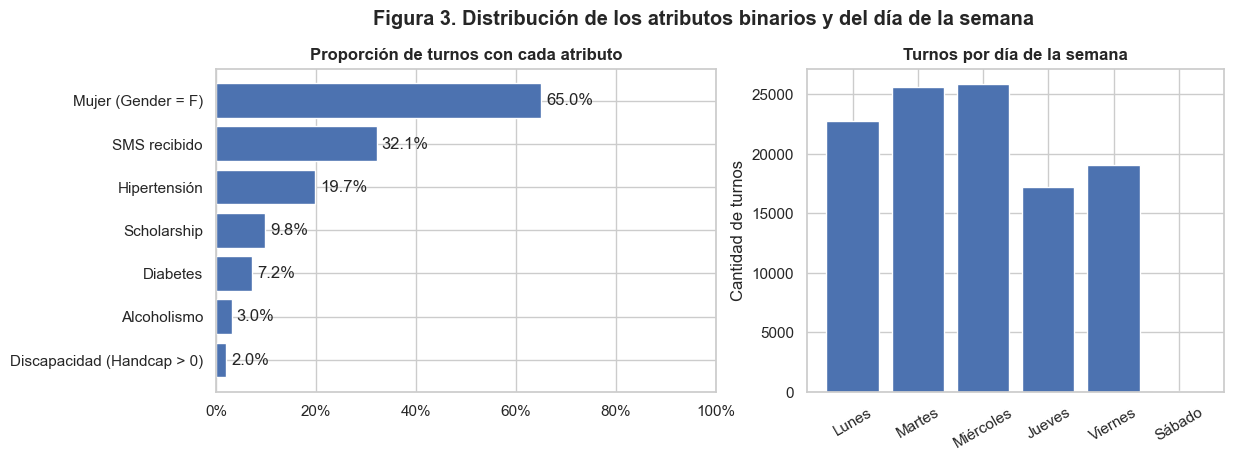

In [20]:
prevalencias = pd.Series({
    "Mujer (Gender = F)": (eda["Gender"] == "F").mean(),
    "Scholarship": eda["Scholarship"].mean(),
    "Hipertensión": eda["Hipertension"].mean(),
    "Diabetes": eda["Diabetes"].mean(),
    "Alcoholismo": eda["Alcoholism"].mean(),
    "Discapacidad (Handcap > 0)": (eda["Handcap"] > 0).mean(),
    "SMS recibido": eda["SMS_received"].mean(),
}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].barh(prevalencias.index, prevalencias.values, color=COLOR_ASISTE)
for i, v in enumerate(prevalencias.values):
    axes[0].text(v + 0.01, i, f"{v:.1%}", va="center")
axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("Proporción de turnos con cada atributo")

dias = eda["dia_semana"].value_counts().reindex(DIAS[:6])
axes[1].bar(dias.index, dias.values, color=COLOR_ASISTE)
axes[1].set_title("Turnos por día de la semana")
axes[1].set_ylabel("Cantidad de turnos")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("Figura 3. Distribución de los atributos binarios y del día de la semana", fontweight="bold", y=1.02)
guardar_figura(fig, "eda_03_distribucion_binarias")
plt.show()

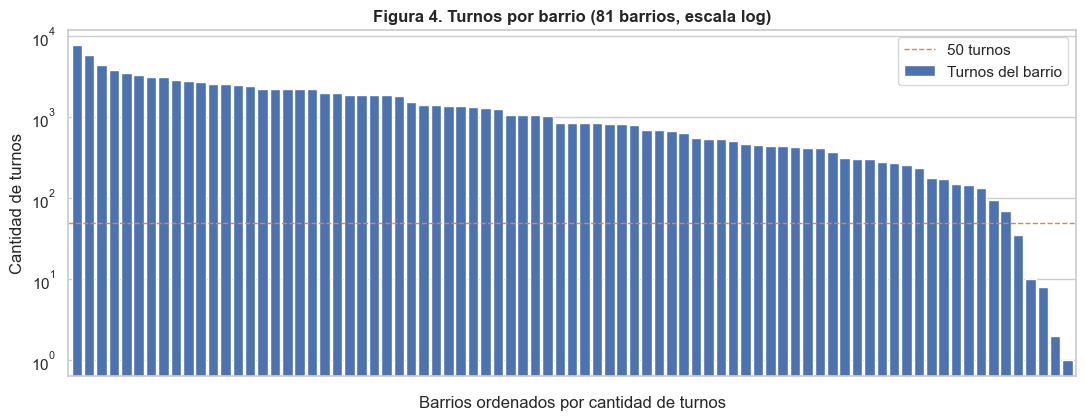

Los 5 barrios más frecuentes concentran el 22.9% de los turnos.


In [21]:
fig, ax = plt.subplots(figsize=(13, 4.5))
conteo_barrios.plot(kind="bar", ax=ax, color=COLOR_ASISTE, width=0.85, label="Turnos del barrio")
ax.grid(axis="x", visible=False)
ax.axhline(UMBRAL_BARRIO, color=COLOR_NO_ASISTE, ls="--", lw=1, label=f"{UMBRAL_BARRIO} turnos")
ax.set_yscale("log")
ax.set_title(f"Figura 4. Turnos por barrio ({conteo_barrios.size} barrios, escala log)")
ax.set_ylabel("Cantidad de turnos")
ax.set_xticklabels([])
ax.set_xlabel("Barrios ordenados por cantidad de turnos")
ax.legend()
guardar_figura(fig, "eda_04_turnos_por_barrio")
plt.show()

top5 = conteo_barrios.head(5).sum() / len(df)
resumen["Turnos concentrados en los 5 barrios más frecuentes"] = f"{top5:.1%}"
print(f"Los 5 barrios más frecuentes concentran el {top5:.1%} de los turnos.")

## 5. Análisis bivariado: relación de cada atributo con el no-show

Para cada atributo se calcula la tasa de no-show por categoría con su intervalo de confianza del 95% (método de Wilson). La línea punteada marca la tasa global: las barras que se alejan de ella, con intervalos que no la cruzan, indican una relación con el ausentismo.

### 5.1. Edad y anticipación

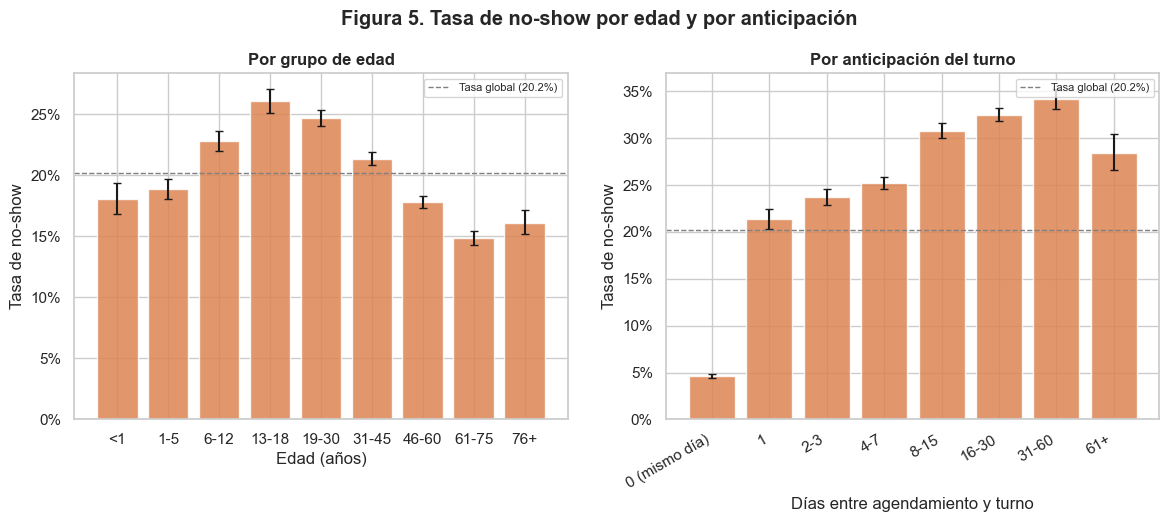

,n,ausencias,tasa,ic_inf,ic_sup
tramo_anticipacion,,,,,
0 (mismo día),38563,1792,0.0465,0.0444,0.0486
1,5213,1113,0.2135,0.2026,0.2248
2-3,9462,2246,0.2374,0.2289,0.2460
4-7,17510,4413,0.2520,0.2457,0.2585
8-15,13528,4166,0.3080,0.3002,0.3158
16-30,15868,5159,0.3251,0.3179,0.3324
31-60,8283,2829,0.3415,0.3314,0.3518
61+,2095,596,0.2845,0.2656,0.3042


In [22]:
eda["grupo_edad"] = pd.cut(eda["Age"], bins=[-np.inf, 0, 5, 12, 18, 30, 45, 60, 75, np.inf],
                           labels=["<1", "1-5", "6-12", "13-18", "19-30", "31-45", "46-60", "61-75", "76+"])
eda["tramo_anticipacion"] = pd.cut(eda["anticipacion_dias"], bins=[-1, 0, 1, 3, 7, 15, 30, 60, np.inf],
                                   labels=["0 (mismo día)", "1", "2-3", "4-7", "8-15", "16-30", "31-60", "61+"])

t_edad = tasa_por(eda, "grupo_edad")
t_ant = tasa_por(eda[eda["anticipacion_dias"] >= 0], "tramo_anticipacion")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
graficar_tasa(axes[0], t_edad, "Por grupo de edad", "Edad (años)")
graficar_tasa(axes[1], t_ant, "Por anticipación del turno", "Días entre agendamiento y turno", rotar=30)
fig.suptitle("Figura 5. Tasa de no-show por edad y por anticipación", fontweight="bold", y=1.02)
guardar_figura(fig, "eda_05_tasa_edad_anticipacion")
plt.show()

guardar_tabla(t_edad, "eda_tasa_grupo_edad", index=True)
guardar_tabla(t_ant, "eda_tasa_anticipacion", index=True)
resumen["No-show en turnos del mismo día"] = f"{t_ant.iloc[0]['tasa']:.1%}"
resumen["No-show en turnos con 1 o más días de anticipación"] = (
    f"{eda.loc[eda['anticipacion_dias'] > 0, 'no_show'].mean():.1%}"
)
t_ant

### 5.2. Atributos binarios y día de la semana

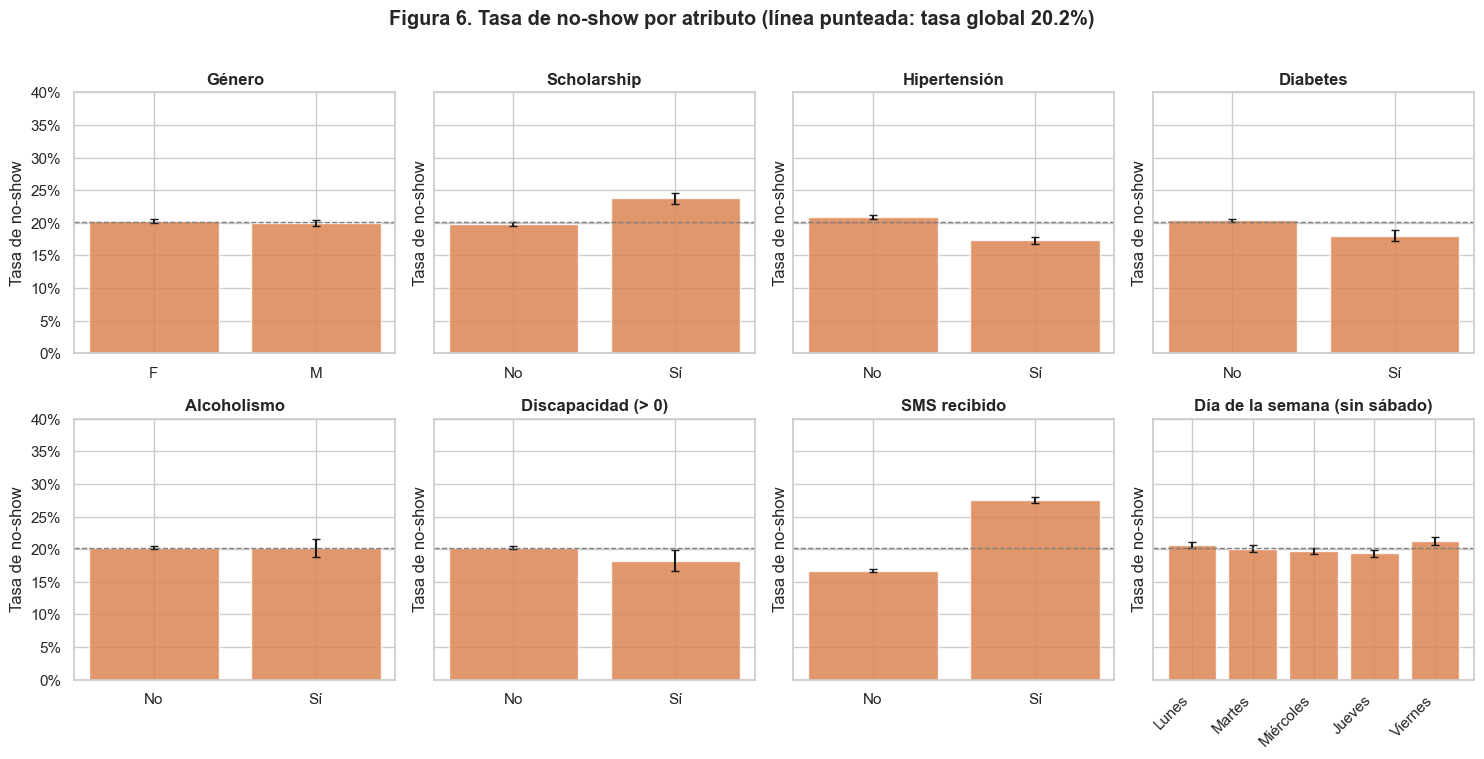

In [23]:
eda["discapacidad"] = (eda["Handcap"] > 0).astype(int)
binarios_graf = {
    "Gender": "Género", "Scholarship": "Scholarship", "Hipertension": "Hipertensión",
    "Diabetes": "Diabetes", "Alcoholism": "Alcoholismo", "discapacidad": "Discapacidad (> 0)",
    "SMS_received": "SMS recibido",
}
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), sharey=True)
for ax, (col, titulo) in zip(axes.flat, binarios_graf.items()):
    t = tasa_por(eda, col)
    if col != "Gender":
        t.index = t.index.map({0: "No", 1: "Sí"})
    graficar_tasa(ax, t, titulo)
    ax.set_ylim(0, 0.4)
    ax.get_legend().remove()
graficar_tasa(axes.flat[-1], tasa_por(eda, "dia_semana", orden=DIAS[:5]), "Día de la semana (sin sábado)", rotar=45)
axes.flat[-1].set_ylim(0, 0.4)
axes.flat[-1].get_legend().remove()
fig.suptitle(f"Figura 6. Tasa de no-show por atributo (línea punteada: tasa global {TASA_GLOBAL:.1%})",
             fontweight="bold", y=1.01)
fig.tight_layout()
guardar_figura(fig, "eda_06_tasa_binarias")
plt.show()

### 5.3. Barrios

Con muchos barrios de pocos turnos, las tasas de los barrios chicos son muy inestables. El gráfico muestra la tasa de cada barrio contra su cantidad de turnos: la dispersión de los barrios chicos es ruido estadístico, no una diferencia real.

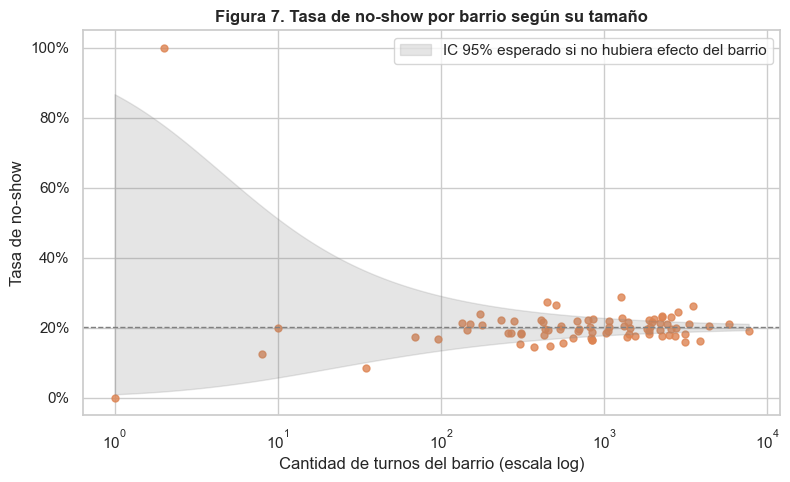

Barrios cuya tasa difiere significativamente de la global: 31 de 81


In [24]:
t_barrio = tasa_por(eda, "Neighbourhood").sort_values("n", ascending=False)
guardar_tabla(t_barrio, "eda_tasa_barrio", index=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(t_barrio["n"], t_barrio["tasa"], s=25, color=COLOR_NO_ASISTE, alpha=0.8)
n_grid = np.logspace(0, np.log10(t_barrio["n"].max()), 200)
_, inf, sup = tasa_con_ic(TASA_GLOBAL * n_grid, n_grid)
ax.fill_between(n_grid, inf, sup, color="gray", alpha=0.2, label="IC 95% esperado si no hubiera efecto del barrio")
ax.axhline(TASA_GLOBAL, color="gray", ls="--", lw=1)
ax.set_xscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Cantidad de turnos del barrio (escala log)")
ax.set_ylabel("Tasa de no-show")
ax.set_title("Figura 7. Tasa de no-show por barrio según su tamaño")
ax.legend(loc="upper right")
guardar_figura(fig, "eda_07_tasa_barrios")
plt.show()

fuera = ((t_barrio["ic_inf"] > TASA_GLOBAL) | (t_barrio["ic_sup"] < TASA_GLOBAL)).sum()
print(f"Barrios cuya tasa difiere significativamente de la global: {fuera} de {len(t_barrio)}")

### 5.4. Pruebas de asociación con la variable objetivo

Con más de 100 mil registros casi cualquier diferencia resulta estadísticamente significativa, por lo que el p-valor solo no sirve para ordenar los atributos. Se reporta además el **tamaño del efecto**:

- **Atributos categóricos:** prueba chi-cuadrado de independencia y **V de Cramér** (0 = sin asociación, 1 = asociación perfecta).
- **Atributos numéricos:** prueba U de Mann-Whitney (no asume normalidad) y **correlación biserial de rangos** (entre -1 y 1; positiva si los valores son más altos en los turnos con ausencia).

In [25]:
def chi2_cramer(col):
    tabla = pd.crosstab(eda[col], eda["no_show"])
    chi2, p, gl, esperado = stats.chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    return {"Prueba": "Chi-cuadrado", "Estadístico": chi2, "gl": gl, "p-valor": p, "Tamaño del efecto": v,
            "Medida": "V de Cramér", "Celdas con esperado < 5": int((esperado < 5).sum())}


def mann_whitney(col):
    datos = eda[eda["anticipacion_dias"] >= 0] if col == "anticipacion_dias" else eda
    a, b = datos.loc[datos["no_show"] == 1, col], datos.loc[datos["no_show"] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {"Prueba": "Mann-Whitney U", "Estadístico": u, "gl": np.nan, "p-valor": p,
            "Tamaño del efecto": 2 * u / (len(a) * len(b)) - 1, "Medida": "Biserial de rangos",
            "Celdas con esperado < 5": np.nan}


pruebas = {c: chi2_cramer(c) for c in ["Gender", "Scholarship", "Hipertension", "Diabetes", "Alcoholism",
                                       "Handcap", "SMS_received", "dia_semana", "Neighbourhood"]}
pruebas.update({c: mann_whitney(c) for c in ["Age", "anticipacion_dias"]})
pruebas = pd.DataFrame(pruebas).T
pruebas["|efecto|"] = pruebas["Tamaño del efecto"].astype(float).abs()
pruebas = pruebas.sort_values("|efecto|", ascending=False).drop(columns="|efecto|")
pruebas.index.name = "Atributo"
guardar_tabla(pruebas, "eda_pruebas_asociacion", index=True)
pruebas

,Prueba,Estadístico,gl,p-valor,Tamaño del efecto,Medida,Celdas con esperado < 5
Atributo,,,,,,,
anticipacion_dias,Mann-Whitney U,"1,374,387,417.0000",NaN,0.0000,0.3965,Biserial de rangos,NaN
SMS_received,Chi-cuadrado,"1,766.0677",1,0.0000,0.1264,V de Cramér,0
Age,Mann-Whitney U,"897,685,520.0000",NaN,0.0000,-0.0880,Biserial de rangos,NaN
Neighbourhood,Chi-cuadrado,491.9279,80,0.0000,0.0667,V de Cramér,6
Hipertension,Chi-cuadrado,140.6514,1,0.0000,0.0357,V de Cramér,0
Scholarship,Chi-cuadrado,93.5772,1,0.0000,0.0291,V de Cramér,0
dia_semana,Chi-cuadrado,27.4685,5,0.0000,0.0158,V de Cramér,0
Diabetes,Chi-cuadrado,25.3226,1,0.0000,0.0151,V de Cramér,0
Handcap,Chi-cuadrado,7.0346,4,0.1341,0.0080,V de Cramér,3


### 5.5. ¿El SMS aumenta el ausentismo? Análisis de una variable de confusión

En la Figura 6 los turnos con SMS muestran **más** ausencias que los turnos sin SMS, lo que contradice lo esperado de un recordatorio. Una explicación posible es que el SMS se envía solo a turnos agendados con varios días de anticipación, y la anticipación es justamente el atributo más asociado al no-show. Si es así, la anticipación es una **variable de confusión**: para ver el efecto real del SMS hay que compararlo **dentro de cada tramo de anticipación**.

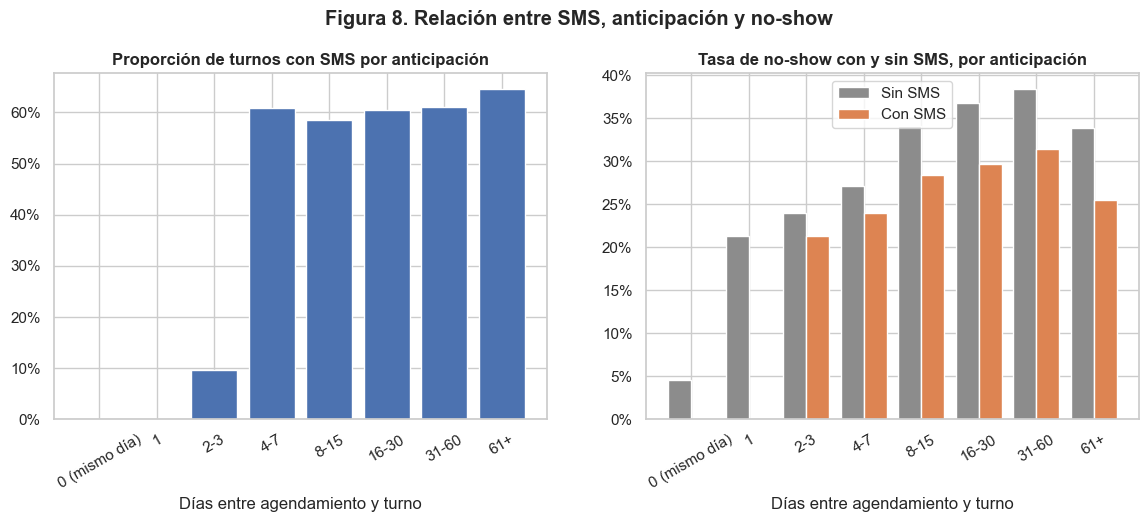

n               tasa       
SMS_received                 0           1      0      1
tramo_anticipacion                                      
0 (mismo día)      38,563.0000         NaN 0.0465    NaN
1                   5,213.0000         NaN 0.2135    NaN
2-3                 8,556.0000    906.0000 0.2399 0.2130
4-7                 6,868.0000 10,642.0000 0.2711 0.2397
8-15                5,601.0000  7,927.0000 0.3412 0.2845
16-30               6,271.0000  9,597.0000 0.3684 0.2969
31-60               3,224.0000  5,059.0000 0.3837 0.3147
61+                   744.0000  1,351.0000 0.3387 0.2546

In [26]:
datos_sms = eda[eda["anticipacion_dias"] >= 0]
envio_sms = datos_sms.groupby("tramo_anticipacion", observed=True)["SMS_received"].mean()
tasa_sms = (datos_sms.groupby(["tramo_anticipacion", "SMS_received"], observed=True)["no_show"]
            .agg(n="size", tasa="mean").unstack("SMS_received"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(envio_sms.index.astype(str), envio_sms.values, color=COLOR_ASISTE)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("Proporción de turnos con SMS por anticipación")
axes[0].set_xlabel("Días entre agendamiento y turno")
axes[0].tick_params(axis="x", rotation=30)

x = np.arange(len(tasa_sms))
for desplazamiento, sms, color, etiqueta in [(-0.2, 0, "#8C8C8C", "Sin SMS"), (0.2, 1, COLOR_NO_ASISTE, "Con SMS")]:
    if ("tasa", sms) in tasa_sms.columns:
        axes[1].bar(x + desplazamiento, tasa_sms[("tasa", sms)], width=0.4, color=color, label=etiqueta)
axes[1].set_xticks(x)
axes[1].set_xticklabels(tasa_sms.index.astype(str), rotation=30)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set_title("Tasa de no-show con y sin SMS, por anticipación")
axes[1].set_xlabel("Días entre agendamiento y turno")
axes[1].legend()

fig.suptitle("Figura 8. Relación entre SMS, anticipación y no-show", fontweight="bold", y=1.02)
guardar_figura(fig, "eda_08_sms_confusion")
plt.show()

guardar_tabla(tasa_sms, "eda_sms_por_anticipacion", index=True)
resumen["Turnos del mismo día con SMS"] = f"{envio_sms.iloc[0]:.1%}"
tasa_sms

## 6. Análisis temporal y por paciente

### 6.1. Evolución diaria

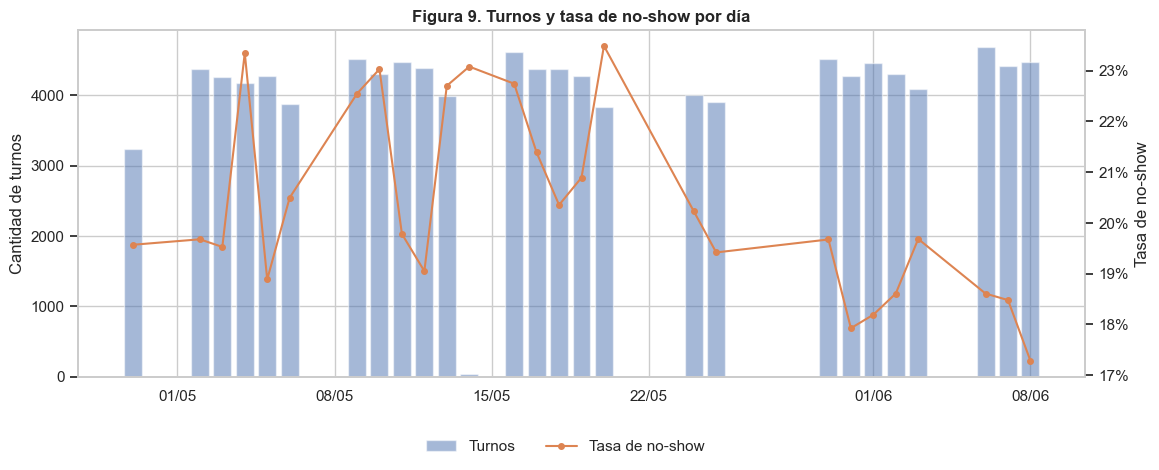

Fecha que deja el 80% de los turnos antes (posible corte temporal): 01/06/2016


In [27]:
diario = eda.groupby(eda["fecha_turno"].dt.date).agg(turnos=("no_show", "size"), tasa=("no_show", "mean"))
diario = diario[diario["turnos"] >= 30]  # se excluyen días con muy pocos turnos (ej. sábados)

fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.bar(pd.to_datetime(diario.index), diario["turnos"], color=COLOR_ASISTE, alpha=0.5, label="Turnos")
ax1.set_ylabel("Cantidad de turnos")
ax2 = ax1.twinx()
ax2.plot(pd.to_datetime(diario.index), diario["tasa"], color=COLOR_NO_ASISTE, marker="o", ms=4, label="Tasa de no-show")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_ylabel("Tasa de no-show")
ax2.grid(False)
ax1.set_title("Figura 9. Turnos y tasa de no-show por día")
import matplotlib.dates as mdates
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
guardar_figura(fig, "eda_09_evolucion_diaria")
plt.show()

corte_80 = eda["fecha_turno"].quantile(0.8)
resumen["Período de turnos"] = f"{eda['fecha_turno'].min():%d/%m/%Y} a {eda['fecha_turno'].max():%d/%m/%Y}"
print(f"Fecha que deja el 80% de los turnos antes (posible corte temporal): {corte_80:%d/%m/%Y}")

### 6.2. Pacientes con varios turnos e historial de ausencias

Si el comportamiento pasado de un paciente predice su comportamiento futuro, conviene construir atributos de historial. Para explorarlo se ordenan los turnos de cada paciente por fecha y se compara la tasa de no-show según el resultado del turno anterior.

> Nota: esta exploración usa el turno inmediatamente anterior aunque sea del mismo día. En la preparación, el historial se calculará solo con turnos de días **estrictamente anteriores**, para evitar fuga de información.

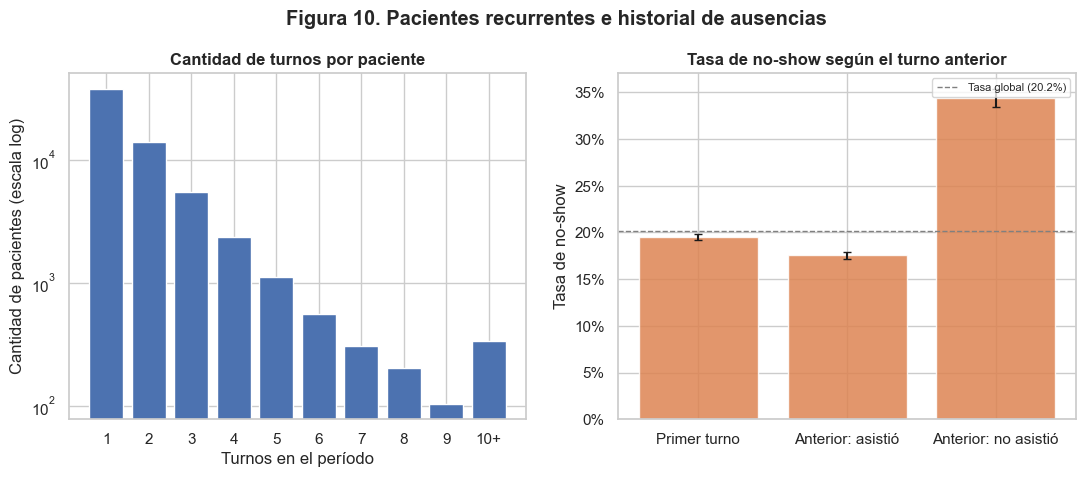

,n,ausencias,tasa,ic_inf,ic_sup
historial,,,,,
Primer turno,62299,12166,0.1953,0.1922,0.1984
Anterior: asistió,38190,6700,0.1754,0.1717,0.1793
Anterior: no asistió,10038,3453,0.3440,0.3348,0.3533


In [28]:
turnos_pac = por_paciente["turnos"]
dist_turnos = turnos_pac.value_counts().sort_index()
pct_recurrentes = (turnos_pac > 1).mean()
pct_turnos_recurrentes = turnos_pac[turnos_pac > 1].sum() / len(eda)

ordenado = eda.sort_values(["PatientId", "fecha_turno", "fecha_agenda", "AppointmentID"])
ordenado["anterior"] = ordenado.groupby("PatientId")["no_show"].shift(1)
ordenado["historial"] = ordenado["anterior"].map({0.0: "Anterior: asistió", 1.0: "Anterior: no asistió"}).fillna("Primer turno")
t_hist = tasa_por(ordenado, "historial", orden=["Primer turno", "Anterior: asistió", "Anterior: no asistió"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tope = 10
dist_plot = pd.concat([dist_turnos[dist_turnos.index < tope], pd.Series({f"{tope}+": dist_turnos[dist_turnos.index >= tope].sum()})])
axes[0].bar(dist_plot.index.astype(str), dist_plot.values, color=COLOR_ASISTE)
axes[0].set_yscale("log")
axes[0].set_title("Cantidad de turnos por paciente")
axes[0].set_xlabel("Turnos en el período")
axes[0].set_ylabel("Cantidad de pacientes (escala log)")
graficar_tasa(axes[1], t_hist, "Tasa de no-show según el turno anterior")
fig.suptitle("Figura 10. Pacientes recurrentes e historial de ausencias", fontweight="bold", y=1.02)
guardar_figura(fig, "eda_10_historial_paciente")
plt.show()

resumen["Pacientes únicos"] = f"{len(por_paciente):,}"
resumen["Pacientes con más de un turno"] = f"{pct_recurrentes:.1%} (concentran el {pct_turnos_recurrentes:.1%} de los turnos)"
resumen["No-show si el turno anterior fue ausencia"] = f"{t_hist.loc['Anterior: no asistió', 'tasa']:.1%}"
resumen["No-show si el turno anterior fue asistencia"] = f"{t_hist.loc['Anterior: asistió', 'tasa']:.1%}"
guardar_tabla(t_hist, "eda_tasa_historial", index=True)
t_hist

## 7. Relaciones entre predictores

Se calcula la correlación de Spearman (basada en rangos, adecuada para variables binarias y asimétricas) entre los predictores y la variable objetivo, para detectar redundancias.

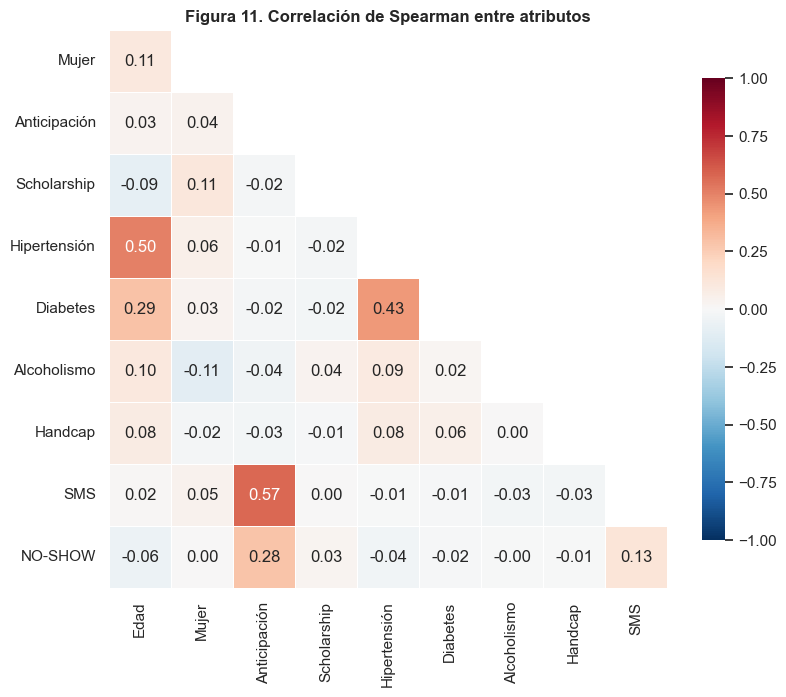

Pares con mayor correlación absoluta:


SMS           Anticipación   0.5733
Hipertensión  Edad           0.5032
Diabetes      Hipertensión   0.4331
              Edad           0.2933
NO-SHOW       Anticipación   0.2816
dtype: float64

In [29]:
eda["mujer"] = (eda["Gender"] == "F").astype(int)
cols_corr = {"Age": "Edad", "mujer": "Mujer", "anticipacion_dias": "Anticipación", "Scholarship": "Scholarship",
             "Hipertension": "Hipertensión", "Diabetes": "Diabetes", "Alcoholism": "Alcoholismo",
             "Handcap": "Handcap", "SMS_received": "SMS", "no_show": "NO-SHOW"}
datos_corr = eda[list(cols_corr)].rename(columns=cols_corr)
corr = datos_corr.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
sub = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(sub, dtype=bool), k=1)
sns.heatmap(sub, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title("Figura 11. Correlación de Spearman entre atributos")
guardar_figura(fig, "eda_11_correlaciones")
plt.show()

pares = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().sort_values(key=abs, ascending=False)
print("Pares con mayor correlación absoluta:")
pares.head(5)

## 8. Síntesis del análisis exploratorio

### 8.1. Cifras clave

In [30]:
cifras = pd.DataFrame(list(resumen.items()), columns=["Indicador", "Valor"])
cifras

,Indicador,Valor
0,Datos utilizados,Dataset completo
1,Instancias (turnos),"110,527"
2,Atributos,14
3,Tasa de no-show,20.19%
4,Relación de clases (asiste : no asiste),3.95 : 1
5,Exactitud del clasificador trivial (clase mayo...,79.81%
6,Turnos agendados para el mismo día,34.9%
7,Edad mediana,37 años
8,Anticipación mediana,4 días
9,Turnos concentrados en los 5 barrios más frecu...,22.9%


### 8.2. Hallazgos y decisiones para la preparación de los datos

| Hallazgo | Decisión para el notebook 02 |
|---|---|
| Desbalance de clases (~4:1) y clasificador trivial con ~80% de exactitud | Métricas PR-AUC, ROC-AUC, recall y F1 de *no-show*; partición estratificada; comparar estrategias de tratamiento solo en entrenamiento; ajustar umbral |
| La anticipación es el atributo más asociado al no-show | Conservar `anticipacion_dias` y evaluar una versión discretizada en tramos y un indicador de turno en el mismo día |
| El efecto aparente del SMS está confundido con la anticipación | Conservar el atributo, pero interpretarlo siempre junto a la anticipación |
| El turno anterior del paciente se asocia fuertemente con el resultado | Crear atributos de historial (turnos previos, ausencias previas) usando solo días estrictamente anteriores |
| Pacientes con varios turnos el mismo día, que en su mayoría tienen el mismo resultado | Partición agrupada por `PatientId` para evitar fuga de información entre entrenamiento y prueba |
| Período de turnos corto (unas 6 semanas) | No se analiza estacionalidad; la partición temporal queda como alternativa a evaluar |
| Edad negativa e implausible, turnos anteriores al agendamiento | Eliminar esas filas (menos del 0,02% del total) |
| `Handcap` es un conteo con valores 2 a 4 muy poco frecuentes | Evaluar binarizar (> 0) |
| Barrios con muy pocos turnos y tasas inestables | Agrupar barrios chicos o usar codificación por frecuencia u objetivo dentro de la validación cruzada |
| Sábados casi inexistentes; `AppointmentDay` sin hora | Agrupar el sábado; no usar la hora del turno |
| Identificadores (`PatientId`, `AppointmentID`) | Excluir como predictores; `PatientId` se usa solo para agrupar |

> Los valores concretos de esta sección deben leerse junto con las cifras calculadas arriba sobre el dataset completo.

### 8.3. Exportación del resumen

In [31]:
lineas = [
    "# Resumen del análisis exploratorio (EDA)",
    "",
    f"**Datos utilizados:** {resumen['Datos utilizados']}",
    "",
    "## Cifras clave",
    "",
    tabla_markdown(cifras),
    "",
    "## Problemas de calidad",
    "",
    tabla_markdown(problemas),
    "",
    "## Clasificadores triviales (validación cruzada estratificada, 5 particiones)",
    "",
    tabla_markdown(baseline_dummy.round(4), index=True),
    "",
    "## Pruebas de asociación con la variable objetivo",
    "",
    tabla_markdown(pruebas[["Prueba", "p-valor", "Tamaño del efecto", "Medida"]], index=True),
    "",
    "## Tasa de no-show por anticipación",
    "",
    tabla_markdown(t_ant[["n", "tasa", "ic_inf", "ic_sup"]].round(4), index=True),
    "",
    "## Tasa de no-show por grupo de edad",
    "",
    tabla_markdown(t_edad[["n", "tasa", "ic_inf", "ic_sup"]].round(4), index=True),
    "",
    "## Tasa de no-show según el turno anterior",
    "",
    tabla_markdown(t_hist[["n", "tasa", "ic_inf", "ic_sup"]].round(4), index=True),
    "",
    "## No-show con y sin SMS por anticipación",
    "",
    tabla_markdown(tasa_sms.set_axis([f"{a}_sms{b}" for a, b in tasa_sms.columns], axis=1).round(4), index=True),
    "",
]
ruta = config.TABLES_DIR / "eda_resumen.md"
ruta.write_text("\n".join(lineas), encoding="utf-8")
print(f"Resumen guardado en: {ruta}")
print(f"Figuras guardadas en: {config.FIGURES_DIR}")

Resumen guardado en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\tables\eda_resumen.md
Figuras guardadas en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\figures
